In [1]:
# Cell 1: import library
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from dotenv import load_dotenv
from urllib.parse import quote_plus
from sqlalchemy import create_engine, text
from pathlib import Path

In [2]:
# Cell 2: connect to MySQL
PROJECT_ROOT = Path.cwd().parent
load_dotenv(PROJECT_ROOT / ".env")
user = os.getenv("MYSQL_USER")
pwd = quote_plus(os.getenv("MYSQL_PASSWORD"))
host = os.getenv("MYSQL_HOST")
port = os.getenv("MYSQL_PORT")
db = os.getenv("MYSQL_DB")
engine = create_engine(f"mysql+pymysql://{user}:{pwd}@{host}:{port}/{db}")
with engine.connect() as conn:
    print("Current database:", conn.execute(text("SELECT DATABASE()")).scalar())

Current database: olist_ecommerce


In [3]:
# Cell 3: columns of the tables this notebook may use
for t in ["orders", "order_items", "order_reviews", "latest_review_t", "products", "sellers"]:
    print(f"--- {t}")
    display(pd.read_sql(text(f"DESCRIBE {t}"), engine)[["Field", "Type"]])

--- orders


,Field,Type
0,order_id,char(32)
1,customer_id,char(32)
2,order_status,varchar(20)
3,order_purchase_timestamp,datetime
4,order_approved_at,datetime
5,order_delivered_carrier_date,datetime
6,order_delivered_customer_date,datetime
7,order_estimated_delivery_date,datetime


--- order_items


,Field,Type
0,order_id,char(32)
1,order_item_id,int
2,product_id,char(32)
3,seller_id,char(32)
4,shipping_limit_date,datetime
5,price,"decimal(10,2)"
6,freight_value,"decimal(10,2)"


--- order_reviews


,Field,Type
0,review_id,char(32)
1,order_id,char(32)
2,review_score,tinyint
3,review_comment_title,varchar(255)
4,review_comment_message,text
5,review_creation_date,datetime
6,review_answer_timestamp,datetime


... (2 outputs left out)

--- products


,Field,Type
0,product_id,char(32)
1,product_category_name,varchar(100)
2,product_name_length,double
3,product_description_length,double
4,product_photos_qty,double
5,product_weight_g,double
6,product_length_cm,double
7,product_height_cm,double
8,product_width_cm,double


--- sellers


,Field,Type
0,seller_id,char(32)
1,seller_zip_code_prefix,int
2,seller_city,varchar(100)
3,seller_state,char(2)


In [4]:
# Cell 4: delivered valid orders with stage timestamps and the latest review
q = """
SELECT v.order_id, v.customer_state,
       v.order_purchase_timestamp, o.order_approved_at, o.order_delivered_carrier_date,
       v.order_delivered_customer_date, v.order_estimated_delivery_date,
       v.revenue, r.review_score
FROM valid_orders_t v
JOIN orders o ON o.order_id = v.order_id
LEFT JOIN latest_review_t r ON r.order_id = v.order_id
WHERE v.order_status = 'delivered' AND v.order_delivered_customer_date IS NOT NULL
"""
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
df = pd.read_sql(text(q), engine, parse_dates=date_cols)
df["revenue"] = df["revenue"].astype(float)

day = pd.Timedelta(days=1)
df["approval_days"] = (df["order_approved_at"] - df["order_purchase_timestamp"]) / day
df["handling_days"] = (df["order_delivered_carrier_date"] - df["order_approved_at"]) / day
df["transit_days"]  = (df["order_delivered_customer_date"] - df["order_delivered_carrier_date"]) / day
df["total_days"]    = (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]) / day
df["est_days"]      = (df["order_estimated_delivery_date"] - df["order_purchase_timestamp"]) / day
df["delay_days"]    = (df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]) / day
df["is_late"] = df["delay_days"] > 0
print(df.shape)

rev = df.dropna(subset=["review_score"])
checks = {
    "delivered orders = 96469":   len(df) == 96469,
    "late rate = 8.11%":          round(df["is_late"].mean() * 100, 2) == 8.11,
    "reviewed on time = 88163":   int((~rev["is_late"]).sum()) == 88163,
    "reviewed late = 7660":       int(rev["is_late"].sum()) == 7660,
    "avg review on time = 4.29":  round(rev.loc[~rev["is_late"], "review_score"].mean(), 2) == 4.29,
    "avg review late = 2.57":     round(rev.loc[rev["is_late"], "review_score"].mean(), 2) == 2.57,
}
for k, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", k)

print("avg total days:", round(df["total_days"].mean(), 2), "(notebook 6: about 12.56)")
print("avg estimated days:", round(df["est_days"].mean(), 2), "(notebook 6: about 23.74)")

(96469, 16)
PASS - delivered orders = 96469
PASS - late rate = 8.11%
PASS - reviewed on time = 88163
PASS - reviewed late = 7660
PASS - avg review on time = 4.29
PASS - avg review late = 2.57
avg total days: 12.56 (notebook 6: about 12.56)
avg estimated days: 23.74 (notebook 6: about 23.74)


In [5]:
# Cell 5: timestamp quality checks and stage durations
print("missing approval time :", int(df["order_approved_at"].isna().sum()))
print("missing carrier date  :", int(df["order_delivered_carrier_date"].isna().sum()))
for c in ["approval_days", "handling_days", "transit_days", "total_days"]:
    print(f"negative {c:14s}:", int((df[c] < 0).sum()))

stages = df[["approval_days", "handling_days", "transit_days", "total_days"]]
display(stages.describe(percentiles=[0.5, 0.9, 0.99]).round(2))

# do the three stages add up to the total? (only rows where all timestamps exist)
ok = stages.dropna()
print("rows with all stages:", len(ok))
print("max |stages sum - total| in days:",
      round((ok["approval_days"] + ok["handling_days"] + ok["transit_days"] - ok["total_days"]).abs().max(), 6))

missing approval time : 14
missing carrier date  : 1
negative approval_days : 0
negative handling_days : 1350
negative transit_days  : 23
negative total_days    : 0


,approval_days,handling_days,transit_days,total_days
count,96455.00,96454.00,96468.00,96469.00
mean,0.43,2.80,9.33,12.56
std,0.86,3.53,8.76,9.55
min,0.00,-171.22,-16.10,0.53
50%,0.01,1.82,7.10,10.22
90%,1.44,5.99,18.90,23.10
99%,3.74,17.05,40.98,46.04
max,30.89,125.76,205.19,209.63


rows with all stages: 96454
max |stages sum - total| in days: 0.0


In [6]:
# Cell 6: stage durations for on-time vs late orders (rows with valid stage times only)
stage_cols = ["approval_days", "handling_days", "transit_days"]
df["valid_stages"] = df[stage_cols].notna().all(axis=1) & (df[stage_cols] >= 0).all(axis=1)
print("rows with valid stage times:", int(df["valid_stages"].sum()), "of", len(df))
print("excluded (missing or negative):", int((~df["valid_stages"]).sum()))

s = df[df["valid_stages"]]
cols = stage_cols + ["total_days", "est_days"]

mean_tbl = s.groupby("is_late")[cols].mean().round(2)
mean_tbl.index = ["on time", "late"]
print("\nMean days")
display(mean_tbl)

median_tbl = s.groupby("is_late")[cols].median().round(2)
median_tbl.index = ["on time", "late"]
print("Median days")
display(median_tbl)

share = s.groupby("is_late")[stage_cols].sum().div(s.groupby("is_late")["total_days"].sum(), axis=0) * 100
share.index = ["on time", "late"]
print("Share of total delivery time (%)")
display(share.round(1))

print("Extra days for late orders (late mean - on-time mean):")
display((mean_tbl.loc["late"] - mean_tbl.loc["on time"]).round(2))

rows with valid stage times: 95081 of 96469
excluded (missing or negative): 1388

Mean days


,approval_days,handling_days,transit_days,total_days,est_days
on time,0.39,2.63,7.91,10.93,23.90
late,0.50,5.34,25.68,31.53,21.97


Median days


,approval_days,handling_days,transit_days,total_days,est_days
on time,0.01,1.78,6.93,9.79,23.30
late,0.02,3.02,23.93,29.18,22.23


Share of total delivery time (%)


,approval_days,handling_days,transit_days
on time,3.6,24.1,72.4
late,1.6,16.9,81.5


Extra days for late orders (late mean - on-time mean):


approval_days     0.11
handling_days     2.71
transit_days     17.77
total_days       20.60
est_days         -1.93
dtype: float64

PASS - reviewed orders = 95823
PASS - late reviewed orders = 7660


,orders,avg_review,bad_review_pct,one_star_pct
delay_group,,,,
early 14+,34771,4.32,9.04,6.54
early 7-14,36158,4.31,8.91,6.41
early 3-7,12529,4.23,9.87,6.74
early 0-3,4705,4.13,11.22,7.95
late 0-2,2100,3.92,15.24,10.29
late 2-5,1468,2.81,46.19,38.69
late 5-10,1861,1.89,73.89,64.43
late 10-20,1382,1.66,80.39,70.19
late 20+,849,1.76,77.39,69.02


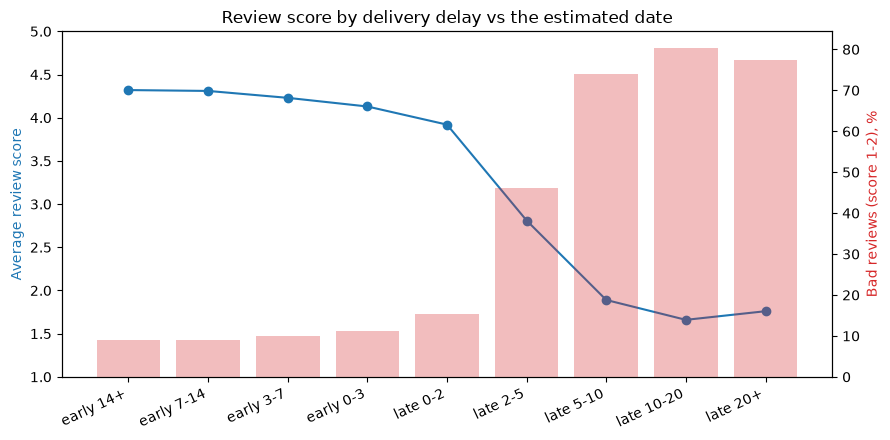

In [7]:
# Cell 7: review score and bad-review share by delay group
bins = [-np.inf, -14, -7, -3, 0, 2, 5, 10, 20, np.inf]
labels = ["early 14+", "early 7-14", "early 3-7", "early 0-3",
          "late 0-2", "late 2-5", "late 5-10", "late 10-20", "late 20+"]
rev = df.dropna(subset=["review_score"]).copy()
rev["delay_group"] = pd.cut(rev["delay_days"], bins=bins, labels=labels)   # (a, b]: a delay of exactly 0 is on time

print("PASS" if len(rev) == 95823 else "FAIL", "- reviewed orders = 95823")
late_n = rev["delay_group"].isin(labels[4:]).sum()
print("PASS" if late_n == 7660 else "FAIL", "- late reviewed orders = 7660")

curve = rev.groupby("delay_group", observed=True).agg(
    orders=("order_id", "size"),
    avg_review=("review_score", "mean"),
    bad_review_pct=("review_score", lambda x: (x <= 2).mean() * 100),
    one_star_pct=("review_score", lambda x: (x == 1).mean() * 100),
).round(2)
display(curve)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(curve.index.astype(str), curve["avg_review"], marker="o", color="tab:blue")
ax.set_ylabel("Average review score", color="tab:blue")
ax.set_ylim(1, 5)
ax2 = ax.twinx()
ax2.bar(curve.index.astype(str), curve["bad_review_pct"], alpha=0.3, color="tab:red")
ax2.set_ylabel("Bad reviews (score 1-2), %", color="tab:red")
ax.set_title("Review score by delivery delay vs the estimated date")
ax.set_xticks(range(len(curve)))
ax.set_xticklabels(curve.index.astype(str), rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [8]:
# Cell 8: bad reviews (score 1-2) and how many come from late orders
rev["bad"] = rev["review_score"] <= 2
t = rev.groupby("is_late")["bad"].agg(orders="size", bad_reviews="sum")
t["bad_rate_pct"] = t["bad_reviews"] / t["orders"] * 100
t.index = ["on time", "late"]
display(t.round(2))

total_bad = int(t["bad_reviews"].sum())
late_bad = int(t.loc["late", "bad_reviews"])
print(f"total bad reviews: {total_bad}")
print(f"bad reviews from late orders: {late_bad} ({late_bad / total_bad * 100:.1f}% of all bad reviews, "
      f"from {t.loc['late', 'orders'] / t['orders'].sum() * 100:.1f}% of reviewed orders)")

# rough upper bound: bad reviews that would disappear if late orders had the on-time bad-review rate
extra = late_bad - t.loc["late", "orders"] * t.loc["on time", "bad_rate_pct"] / 100
print(f"extra bad reviews linked to lateness: about {extra:.0f} ({extra / total_bad * 100:.1f}% of all bad reviews)")

,orders,bad_reviews,bad_rate_pct
on time,88163,8130,9.22
late,7660,4141,54.06


total bad reviews: 12271
bad reviews from late orders: 4141 (33.7% of all bad reviews, from 8.0% of reviewed orders)
extra bad reviews linked to lateness: about 3435 (28.0% of all bad reviews)


In [9]:
# Cell 9: order-level item features, merged with the delivery table
q = """
WITH it AS (
  SELECT i.order_id, i.order_item_id, i.seller_id, i.price, i.freight_value,
         p.product_category_name, p.product_weight_g,
         ROW_NUMBER() OVER (PARTITION BY i.order_id ORDER BY i.price DESC, i.order_item_id) AS rn
  FROM order_items i
  JOIN valid_orders_t v ON v.order_id = i.order_id
  JOIN products p ON p.product_id = i.product_id
)
SELECT order_id, COUNT(*) AS n_items, COUNT(DISTINCT seller_id) AS n_sellers,
       SUM(price) AS items_price, SUM(freight_value) AS freight, SUM(product_weight_g) AS weight_g,
       MAX(CASE WHEN rn = 1 THEN seller_id END) AS main_seller,
       MAX(CASE WHEN rn = 1 THEN product_category_name END) AS main_category
FROM it GROUP BY order_id
"""
items = pd.read_sql(text(q), engine)
for c in ["items_price", "freight"]:
    items[c] = items[c].astype(float)

full = df.merge(items, on="order_id", how="left")
print("PASS" if len(full) == 96469 else "FAIL", "- rows after merge = 96469")
print("orders without item features:", int(full["n_items"].isna().sum()))
print("missing weight:", int(full["weight_g"].isna().sum()), "| missing category:", int(full["main_category"].isna().sum()))
print("multi-item orders:", int((full["n_items"] > 1).sum()), "| multi-seller orders:", int((full["n_sellers"] > 1).sum()))
full[["n_items", "n_sellers", "items_price", "freight", "weight_g"]].describe().round(2)

PASS - rows after merge = 96469
orders without item features: 0
missing weight: 16 | missing category: 1358
multi-item orders: 9634 | multi-seller orders: 1275


,n_items,n_sellers,items_price,freight,weight_g
count,96469.00,96469.00,96469.00,96469.00,96453.00
mean,1.14,1.01,137.04,22.79,2386.86
std,0.54,0.12,209.05,21.56,4770.13
min,1.00,1.00,0.85,0.00,0.00
25%,1.00,1.00,45.90,13.85,300.00
50%,1.00,1.00,86.50,17.17,750.00
75%,1.00,1.00,149.90,24.02,2050.00
max,21.00,5.00,13440.00,1794.96,184400.00


In [10]:
# Cell 10: late rate by main category and concentration of late orders in sellers
cat = full.assign(category=full["main_category"].fillna("unknown")).groupby("category").agg(
    orders=("order_id", "size"),
    late_rate_pct=("is_late", lambda s: s.mean() * 100),
    avg_review=("review_score", "mean"),
)
cat = cat[cat["orders"] >= 500].sort_values("late_rate_pct", ascending=False).round(2)
print("Categories with 500+ delivered orders, highest late rate first")
display(cat.head(10))
print("Overall late rate: 8.11%")

sl = full.groupby("main_seller").agg(orders=("order_id", "size"), late=("is_late", "sum"))
sl = sl.sort_values("late", ascending=False)
n10 = int(np.ceil(len(sl) * 0.10))
share_late = sl["late"].iloc[:n10].sum() / sl["late"].sum() * 100
share_orders = sl["orders"].iloc[:n10].sum() / sl["orders"].sum() * 100
print(f"\nsellers: {len(sl)}")
print(f"top 10% of sellers by late orders ({n10} sellers): {share_late:.1f}% of late orders, {share_orders:.1f}% of all orders")

Categories with 500+ delivered orders, highest late rate first


,orders,late_rate_pct,avg_review
category,,,
eletronicos,2502,9.87,4.13
bebes,2761,9.27,4.12
construcao_ferramentas_construcao,724,9.25,4.15
moveis_escritorio,1251,9.19,3.65
unknown,1358,8.98,4.04
beleza_saude,8612,8.98,4.23
instrumentos_musicais,608,8.88,4.24
cama_mesa_banho,9184,8.81,4.01
automotivo,3792,8.65,4.15


Overall late rate: 8.11%

sellers: 2959
top 10% of sellers by late orders (296 sellers): 72.7% of late orders, 63.3% of all orders


In [11]:
# Cell 11: logistic regression, bad review ~ late + controls (odds ratios)
import statsmodels.formula.api as smf   # if missing: pip install statsmodels, then restart the kernel

d = full.dropna(subset=["review_score", "weight_g"]).copy()
d["bad"] = (d["review_score"] <= 2).astype(int)
d["late"] = d["is_late"].astype(int)
top_cats = d["main_category"].value_counts().head(15).index
d["cat_grp"] = np.where(d["main_category"].isna(), "unknown",
                np.where(d["main_category"].isin(top_cats), d["main_category"], "other"))
d["log_price"] = np.log1p(d["items_price"])
d["log_freight"] = np.log1p(d["freight"])
d["log_weight"] = np.log1p(d["weight_g"])
print("orders in the model:", len(d), "(95823 reviewed orders minus those with missing weight)")

m0 = smf.logit("bad ~ late", d).fit(disp=0)
m1 = smf.logit("bad ~ late + C(customer_state) + C(cat_grp) + log_price + log_freight + log_weight + n_items", d).fit(disp=0)

def odds(m, names):
    ci = np.exp(m.conf_int().loc[names])
    return pd.DataFrame({"odds_ratio": np.exp(m.params[names]), "ci_low": ci[0], "ci_high": ci[1]}).round(2)

print("Without controls (check: (54.06/45.94) / (9.22/90.78) is about 11.6):")
display(odds(m0, ["late"]))
print("With controls:")
display(odds(m1, ["late", "log_price", "log_freight", "log_weight", "n_items"]))
print("converged:", m1.mle_retvals["converged"], "| pseudo R-squared: model 1 =", round(m1.prsquared, 3), "model 0 =", round(m0.prsquared, 3))

orders in the model: 95807 (95823 reviewed orders minus those with missing weight)
Without controls (check: (54.06/45.94) / (9.22/90.78) is about 11.6):


,odds_ratio,ci_low,ci_high
late,11.59,11.02,12.19


With controls:


,odds_ratio,ci_low,ci_high
late,11.93,11.33,12.57
log_price,1.03,1.00,1.06
log_freight,1.28,1.21,1.36
log_weight,0.99,0.97,1.02
n_items,1.61,1.55,1.67


converged: True | pseudo R-squared: model 1 = 0.142 model 0 = 0.116


## Delivery and review findings

**Data:** 96,469 delivered valid orders (95,823 with a review). Reconciles with notebooks 6 and 7: late rate 8.11%, average review 4.29 on time and 2.57 late, average delivery 12.56 days against 23.74 estimated.

### 1. Where the time goes
- Stage times use 95,081 orders. 1,388 were excluded: 14 with a missing approval time, 1 with a missing carrier date, 1,350 with a carrier handover dated before the approval and 23 with a delivery dated before the handover (the three stages add up exactly to the total, so only the split between stages is affected).
- Late orders take 31.53 days on average against 10.93 for on-time orders, 20.60 days longer.
- **86% of the extra time is in the carrier-to-customer stage** (17.77 days). Handling adds 2.71 days (13%) and approval 0.11 days. Median transit is 23.93 days for late orders against 6.93 for on-time ones.
- Late orders were not given looser estimates (21.97 estimated days against 23.90 for on-time orders). Their transit ran much longer than expected.
- The data shows where the time goes, not why transit is slow.

### 2. Review score by delay
- Orders 7+ days early average 4.31 to 4.32. The score declines gently up to the deadline: 4.13 for 0 to 3 days early and 3.92 for 0 to 2 days late (15.24% bad reviews).
- **The sharp drop is at 2 to 5 days late:** the average falls to 2.81 and bad reviews (score 1-2) rise from 15.24% to 46.19%.
- From 5 days late the average is 1.89, and from 10 days it levels off at about 1.7 (1.66 for 10 to 20 days late, 1.76 beyond 20; the last group has only 849 orders).

### 3. How many bad reviews are linked to late delivery
- Bad-review rate: 54.06% for late orders against 9.22% for on-time orders.
- Late orders are 8.0% of reviewed orders but 33.7% of all bad reviews (4,141 of 12,271).
- At the on-time bad-review rate, about 3,435 bad reviews (28.0% of all) would not exist. This is an upper bound.
- **66.3% of bad reviews come from on-time orders,** so late delivery is a major driver but not the only one.

### 4. Categories and sellers
- Late rates by main category are close together: the highest are eletronicos (electronics) 9.87%, bebes (baby) 9.27% and construcao_ferramentas_construcao (construction tools) 9.25%, against 8.11% overall (categories with 500+ orders).
- moveis_escritorio (office furniture) has a late rate of 9.19% but the lowest average review (3.65), so its low scores are not explained by lateness.
- The top 10% of sellers by late orders (296 of 2,959) account for 72.7% of late orders and 63.3% of all orders. Late deliveries come mostly from high-volume sellers, with only modest concentration beyond volume.

### 5. Does the late-delivery effect hold after controls?
Logistic regression on 95,807 orders, outcome = bad review (score 1-2), controls = customer state, main category, log price, log freight, log weight and number of items.

| Term | Odds ratio | 95% CI |
|---|---|---|
| Late (no controls) | 11.59 | 11.02 to 12.19 |
| Late (with controls) | 11.93 | 11.33 to 12.57 |
| Number of items (per extra item) | 1.61 | 1.55 to 1.67 |
| Log freight | 1.28 | 1.21 to 1.36 |
| Log price | 1.03 | 1.00 to 1.06 |
| Log weight | 0.99 | 0.97 to 1.02 |

- The odds of a bad review are about 12 times higher for late orders, and the controls do not weaken this, so the link is not just a state, category, price or freight effect.
- Orders with more items have higher odds of a bad review. The pseudo R-squared rises only from 0.116 to 0.142, so the controls add little.

### Limits
- Observational data: the results show associations, not causes. Product quality and other factors without data could also play a part.
- Only reviewed orders are used for review results. Customers with a bad experience may be more likely to review.
- "Main seller" and "main category" are those of the highest-priced item, which is a simplification for the 9,634 multi-item orders.
- 1,358 orders (1.4%) have no product category.